# Fase 4 · Laboratorio de análisis y visualización

**MCDI500 · Programación para la Ciencia de Datos · Grupo 8**

Este cuaderno es un **espacio de prueba**: aquí se ensayan los análisis y las figuras que responden la pregunta del proyecto antes de pasarlos al notebook oficial de la Fase 4. No modifica los artefactos de la Fase 3 y guarda sus salidas en carpetas propias (`F4/figuras_lab/` y `docs/hallazgos_f4_lab.csv`).

**Pregunta central:** ¿qué relación existe entre las comodidades, la capacidad y la ubicación de los alojamientos completos de Airbnb Santiago y su precio y ocupación anual estimada?

| Sección | Qué responde |
|---|---|
| 1–2 | Entorno, carga de artefactos y copia interpretable |
| 3 | Decisiones del análisis: ocupación con ceros y tope, comunas pequeñas |
| 4 | **Ubicación**: precio y ocupación por comuna |
| 5 | **Capacidad**: precio y ocupación según huéspedes |
| 6 | **Comodidades**: cantidad de comodidades y precio |
| 7 | **Comodidades**: qué comodidades se asocian a precios altos, y si la diferencia se mantiene al controlar ubicación y capacidad |
| 8 | Estabilidad entre entrenamiento y prueba |
| 9 | Tabla de hallazgos y limitaciones |

**Cómo se ejecuta:** desde la raíz del repositorio o desde `F4/`, con *Restart & Run All*. Solo necesita los cuatro archivos de `data/processed/` que genera la Fase 3; no necesita el archivo crudo.

## 1. Entorno, rutas y estilo de las figuras

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

SEMILLA = 42
np.random.seed(SEMILLA)


def localizar_raiz(inicio=None):
    # Jupyter abre el kernel en F4/; la raíz del proyecto es la carpeta superior
    actual = Path(inicio or Path.cwd()).resolve()
    return actual.parent if actual.name in {"F1", "F2", "F3", "F4"} else actual


RAIZ = localizar_raiz()
DIR_PROCESADO = RAIZ / "data" / "processed"
DIR_FIGURAS = RAIZ / "F4" / "figuras_lab"     # carpeta de prueba: no pisa las figuras oficiales
DIR_DOCS = RAIZ / "docs"

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import src.comunicacion as com

print("Entorno    :", "virtual" if sys.prefix != sys.base_prefix else "AVISO: Python del sistema")
print("pandas     :", pd.__version__, "| NumPy:", np.__version__, "| matplotlib:", matplotlib.__version__)
print("Raíz       :", RAIZ.name)   # solo el nombre: no se muestran rutas absolutas del equipo

Entorno    : AVISO: Python del sistema
pandas     : 3.1.1 | NumPy: 2.5.4 | matplotlib: 3.11.2
Raíz       : f4lab


In [2]:
# ---- Estilo: el color tiene una función, no es decoración ----
AZUL = "#2a78d6"       # precio
NARANJA = "#eb6834"    # ocupación / grupo que se contrasta
GRIS = "#a3a29c"       # contexto (por ejemplo, "Otras comunas")
TINTA = "#0b0b0b"      # texto principal
TINTA_2 = "#52514e"    # texto secundario
GRILLA = "#e6e5e1"     # grilla recesiva

FUENTE = "Fuente: Inside Airbnb, Santiago, captura del 23-09-2026. Alojamientos completos (n = {n})."

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlecolor": TINTA,
    "axes.labelsize": 10,
    "axes.labelcolor": TINTA_2,
    "axes.edgecolor": GRIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "grid.color": GRILLA,
    "grid.linewidth": 0.8,
    "xtick.color": TINTA_2,
    "ytick.color": TINTA_2,
    "legend.frameon": False,
    "font.size": 10,
    "text.parse_math": False,   # el signo $ se muestra tal cual (no como fórmula)
})


def miles(valor):
    # Formato chileno: punto de miles, sin decimales (60000 -> 60.000)
    return f"{valor:,.0f}".replace(",", ".")


def decimal(valor, dec=1):
    # Formato chileno: coma decimal (0.18 -> 0,18)
    return f"{valor:.{dec}f}".replace(".", ",")


EJE_CLP = FuncFormatter(lambda v, _: f"${miles(v)}")
EJE_MILES = FuncFormatter(lambda v, _: miles(v))


def pie_de_figura(fig, n, texto_extra="", y=-0.02):
    # Fuente y notas en gris bajo la figura
    nota = FUENTE.format(n=miles(n)) + (f" {texto_extra}" if texto_extra else "")
    fig.text(0.01, y, nota, ha="left", va="top", fontsize=8.5, color=TINTA_2)

---
## 2. Lo que entregó la Fase 3 y la copia interpretable

Los artefactos de la Fase 3 sirven para analizar, pero no para graficar: las comunas están en 30 columnas de ceros y unos, y siete variables están escaladas (sin unidad). Para comunicar se construye una **copia interpretable**: se revierte el escalado con los parámetros guardados en JSON (`x = z × RIC + mediana`) y se recompone la comuna. Los artefactos originales no se modifican.

In [3]:
artefactos = com.cargar_artefactos(DIR_PROCESADO)
parametros = com.leer_parametros(artefactos["parametros"])
entrenamiento, prueba = artefactos["entrenamiento"], artefactos["prueba"]

# El contrato entre fases: mismo esquema, sin nulos
assert list(entrenamiento.columns) == list(prueba.columns), "Entrenamiento y prueba difieren en columnas"
assert entrenamiento.isna().sum().sum() == 0 and prueba.isna().sum().sum() == 0, "Hay nulos"

for nombre, tabla in artefactos.items():
    print(f"{nombre:<14} {tabla.shape[0]:>6} filas x {tabla.shape[1]:>2} columnas")

entrenamiento   11788 filas x 50 columnas
prueba           2970 filas x 50 columnas
parametros         24 filas x  3 columnas
diccionario        50 filas x  4 columnas


In [4]:
ESCALADAS = [p[len("EscaladorRobusto("):-1] for p in parametros if p.startswith("EscaladorRobusto(")]

legible = pd.concat(
    [com.copia_interpretable(entrenamiento, parametros).assign(conjunto="entrenamiento"),
     com.copia_interpretable(prueba, parametros).assign(conjunto="prueba")],
    ignore_index=True,
).rename(columns={"neighbourhood_cleansed": "comuna", "estimated_occupancy_l365d": "ocupacion"})

# Verificación 1: la mediana de entrenamiento revertida es exactamente la guardada por la F3
ent = legible[legible["conjunto"] == "entrenamiento"]
for col in ESCALADAS:
    assert np.isclose(ent[col].median(), parametros[f"EscaladorRobusto({col})"]["mediana"]), col

# Verificación 2: las variables de conteo vuelven a ser números enteros
for col in ["accommodates", "bedrooms", "beds", "n_comodidades", "minimum_nights"]:
    assert np.allclose(legible[col], legible[col].round()), col
    legible[col] = legible[col].round().astype(int)

# Verificación 3: todas las filas recuperan una comuna real
assert (legible["comuna"] != "Otra").all(), "Hay filas sin comuna"

print(f"Copia interpretable: {miles(len(legible))} alojamientos, {legible['comuna'].nunique()} comunas")
print("Las tres verificaciones pasaron: escalado revertido, conteos enteros y comunas completas.")
legible[["comuna", "price", "ocupacion", "accommodates", "bedrooms", "n_comodidades"]].head()

Copia interpretable: 14.758 alojamientos, 30 comunas
Las tres verificaciones pasaron: escalado revertido, conteos enteros y comunas completas.


,comuna,price,ocupacion,accommodates,bedrooms,n_comodidades
0,Ñuñoa,84947.0,36,4,2,44
1,Vitacura,90000.0,0,2,1,7
2,Santiago,43500.0,0,2,1,50
3,Estación Central,40562.0,255,3,1,36
4,Ñuñoa,40000.0,255,2,1,24


---
## 3. Decisiones del análisis

- **Se describen los 14.758 alojamientos** (entrenamiento y prueba juntos), porque la Fase 4 es descriptiva. La partición se usa en la sección 8 para comprobar que los patrones se repiten en ambas partes.
- **Se reportan medianas y rangos intercuartílicos (RIC)**, no medias, porque el precio y la ocupación son muy asimétricos.
- **Comunas con menos de 30 alojamientos** se agrupan en "Otras comunas": con tan pocos casos, su mediana no es estable.
- **La ocupación es una estimación** a partir de las reseñas, con muchos ceros y un tope. Se cuantifican abajo.

In [5]:
oc = legible["ocupacion"]
TOPE = oc.max()
pct_cero = (oc == 0).mean() * 100
pct_tope = (oc == TOPE).mean() * 100
legible["ocupacion_positiva"] = oc.where(oc > 0)    # NaN cuando la ocupación es 0

print(f"Precio      : mediana ${miles(legible['price'].median())} | "
      f"RIC ${miles(legible['price'].quantile(.25))} – ${miles(legible['price'].quantile(.75))}")
print(f"Ocupación   : mediana {miles(oc.median())} noches/año | tope {miles(TOPE)} noches")
print(f"Ocupación 0 : {decimal(pct_cero)} % de los alojamientos")
print(f"En el tope  : {decimal(pct_tope)} % de los alojamientos")

MIN_COMUNA = 30
conteo = legible["comuna"].value_counts()
pequeñas = conteo[conteo < MIN_COMUNA]
legible["comuna_grupo"] = legible["comuna"].where(~legible["comuna"].isin(pequeñas.index),
                                                  f"Otras comunas ({len(pequeñas)})")
print(f"\nComunas con menos de {MIN_COMUNA} alojamientos: {len(pequeñas)} "
      f"(suman {miles(pequeñas.sum())} alojamientos) -> se agrupan")

Precio      : mediana $60.000 | RIC $44.698 – $87.434
Ocupación   : mediana 60 noches/año | tope 255 noches
Ocupación 0 : 17,6 % de los alojamientos
En el tope  : 10,5 % de los alojamientos

Comunas con menos de 30 alojamientos: 12 (suman 120 alojamientos) -> se agrupan


**Cómo se lee.** Casi uno de cada cinco alojamientos tiene ocupación estimada 0 y uno de cada diez está en el tope, así que la ocupación no se distribuye de forma continua. Por eso, en las figuras de ocupación se usan los alojamientos con ocupación mayor que 0 y se informa aparte qué porcentaje tiene ocupación 0 en cada grupo.

In [6]:
def resumen(df, grupo, valor):
    # Mediana, cuartiles y n de una variable por grupo
    g = df.groupby(grupo, observed=True)[valor]
    return pd.DataFrame({"n": g.size(), "mediana": g.median(),
                         "q1": g.quantile(.25), "q3": g.quantile(.75)})


def guardar(fig, nombre):
    ruta = com.guardar_figura(fig, DIR_FIGURAS, nombre)
    print("Figura guardada:", ruta.relative_to(RAIZ))

---
## 4. Ubicación: precio y ocupación por comuna

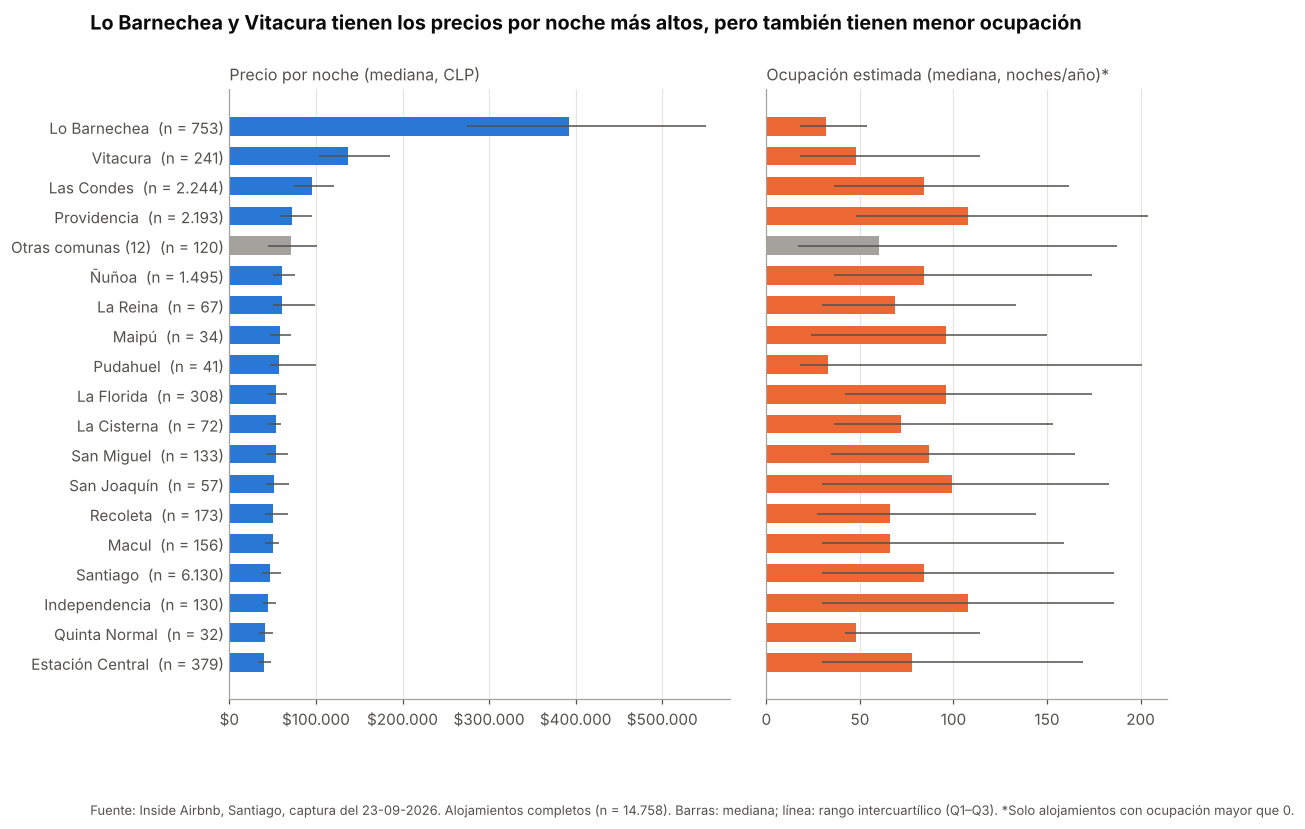

Figura guardada: F4/figuras_lab/lab_fig1_comunas.png


In [7]:
precio_c = resumen(legible, "comuna_grupo", "price")
ocup_c = resumen(legible, "comuna_grupo", "ocupacion_positiva")
ocup_c["pct_cero"] = legible.groupby("comuna_grupo")["ocupacion"].apply(lambda s: (s == 0).mean() * 100)

orden = precio_c.sort_values("mediana").index          # de menor a mayor: la más cara queda arriba
precio_c, ocup_c = precio_c.loc[orden], ocup_c.loc[orden]
y = np.arange(len(orden))
es_otras = orden.str.startswith("Otras")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 7.2), sharey=True,
                             gridspec_kw={"width_ratios": [1.25, 1], "wspace": 0.08})

for eje, tabla, color, titulo in [(a1, precio_c, AZUL, "Precio por noche (mediana, CLP)"),
                                  (a2, ocup_c, NARANJA, "Ocupación estimada (mediana, noches/año)*")]:
    colores = np.where(es_otras, GRIS, color)
    eje.barh(y, tabla["mediana"], height=0.62, color=colores)
    eje.hlines(y, tabla["q1"], tabla["q3"], color=TINTA_2, linewidth=1)   # RIC
    eje.set_title(titulo, fontsize=10.5, color=TINTA_2, fontweight="normal")
    eje.grid(axis="x")
    eje.set_axisbelow(True)
    eje.tick_params(axis="y", length=0)

a1.xaxis.set_major_formatter(EJE_CLP)
a1.set_yticks(y, [f"{c}  (n = {miles(n)})" for c, n in zip(orden, precio_c["n"])])
a2.xaxis.set_major_formatter(EJE_MILES)

top = precio_c.drop(index=orden[es_otras]).sort_values("mediana", ascending=False)
fig.suptitle(f"{top.index[0]} y {top.index[1]} tienen los precios por noche más altos, "
             f"pero también tienen menor ocupación",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TINTA)
pie_de_figura(fig, len(legible),
              "Barras: mediana; línea: rango intercuartílico (Q1–Q3). "
              "*Solo alojamientos con ocupación mayor que 0.")
plt.show()
guardar(fig, "lab_fig1_comunas")

In [8]:
# Las cifras detrás de la figura, para el informe y el video
tabla_comunas = (precio_c[["n", "mediana", "q1", "q3"]]
                 .join(ocup_c[["mediana", "pct_cero"]].add_suffix("_ocup"))
                 .sort_values("mediana", ascending=False))
tabla_comunas.columns = ["n", "precio_mediana", "precio_q1", "precio_q3", "ocup_mediana", "pct_ocup_cero"]
tabla_comunas.round(1)

,n,precio_mediana,precio_q1,precio_q3,ocup_mediana,pct_ocup_cero
comuna_grupo,,,,,,
Lo Barnechea,753,391834.0,275000.0,551051.0,32.0,26.4
Vitacura,241,136666.7,103333.3,185219.0,48.0,32.4
Las Condes,2244,95000.0,75000.0,120616.0,84.0,14.1
Providencia,2193,72550.0,58917.5,95000.0,108.0,14.1
Otras comunas (12),120,70882.0,44618.1,101038.0,60.0,36.7
Ñuñoa,1495,61169.0,50000.0,75608.5,84.0,12.0
La Reina,67,61000.0,50708.0,98750.0,69.0,34.3
Maipú,34,59000.0,46693.0,71397.0,96.0,26.5
Pudahuel,41,57356.0,46491.0,100000.0,33.0,36.6


**Cómo se lee.**
- **Qué muestra:** la mediana del precio por noche y de la ocupación estimada por comuna, con su RIC y el número de alojamientos.
- **Qué se infiere:** el precio se asocia fuertemente a la ubicación. Lo Barnechea ($391.834) supera unas 8 veces a Santiago ($46.577), la comuna con más alojamientos (6.130). Le siguen Vitacura ($136.667), Las Condes ($95.000) y Providencia ($72.550). La ocupación no sigue al precio: las dos comunas más caras tienen las medianas más bajas (32 y 48 noches) y más alojamientos con ocupación 0 (26,4 % y 32,4 %, frente a 14,1 % en Las Condes y Providencia).
- **Límite:** precio publicado, no pagado; ocupación estimada. Parte de la diferencia de Lo Barnechea puede deberse a que tiene alojamientos más grandes (ver sección 5).
- **Cómo aporta:** responde la parte de **ubicación** de la pregunta.

---
## 5. Capacidad: precio y ocupación según número de huéspedes

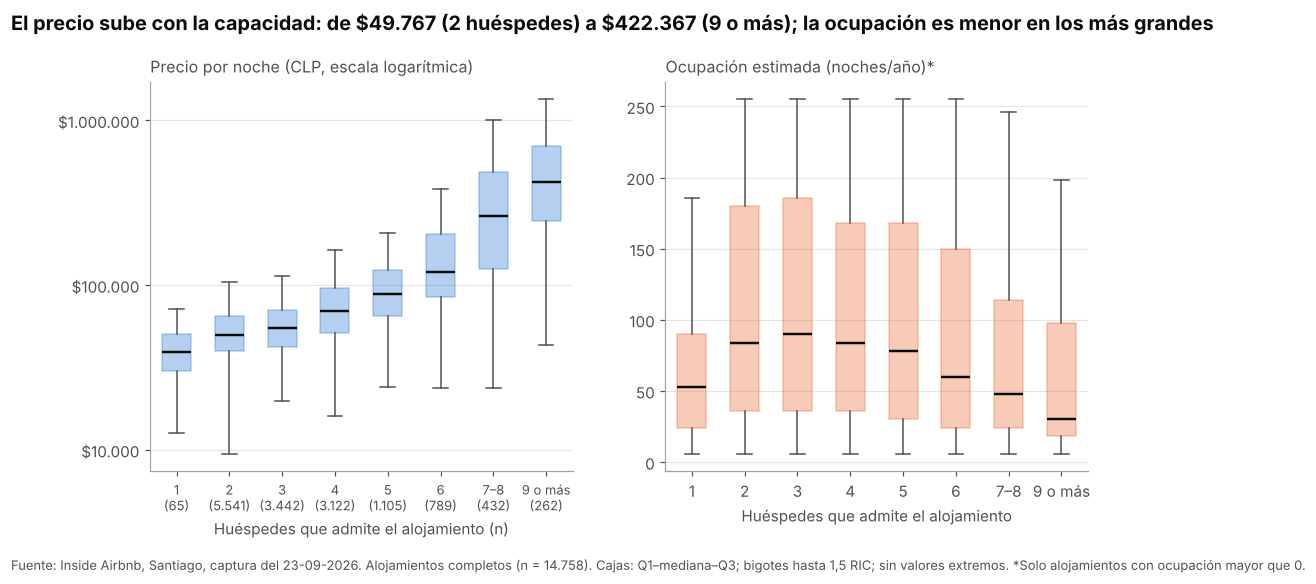

Figura guardada: F4/figuras_lab/lab_fig2_capacidad.png


In [9]:
legible["capacidad"] = pd.cut(legible["accommodates"], bins=[0, 1, 2, 3, 4, 5, 6, 8, np.inf],
                              labels=["1", "2", "3", "4", "5", "6", "7–8", "9 o más"])
grupos = legible["capacidad"].cat.categories

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"wspace": 0.22})

for eje, col, color, titulo, fmt in [
        (a1, "price", AZUL, "Precio por noche (CLP, escala logarítmica)", EJE_CLP),
        (a2, "ocupacion_positiva", NARANJA, "Ocupación estimada (noches/año)*", EJE_MILES)]:
    datos = [legible.loc[legible["capacidad"] == g, col].dropna() for g in grupos]
    cajas = eje.boxplot(datos, tick_labels=grupos, showfliers=False, widths=0.55, patch_artist=True,
                        medianprops={"color": TINTA, "linewidth": 1.6},
                        whiskerprops={"color": TINTA_2}, capprops={"color": TINTA_2},
                        boxprops={"edgecolor": color})
    for caja in cajas["boxes"]:
        caja.set_facecolor(color)
        caja.set_alpha(0.35)
    if col == "price":
        eje.set_yscale("log")   # el precio abarca de miles a millones
    eje.yaxis.set_major_formatter(fmt)
    eje.set_title(titulo, fontsize=10.5, color=TINTA_2, fontweight="normal")
    eje.set_xlabel("Huéspedes que admite el alojamiento" + (" (n)" if col == "price" else ""))
    eje.grid(axis="y")
    eje.set_axisbelow(True)

n_cap = legible["capacidad"].value_counts().reindex(grupos)
a1.set_xticks(range(1, len(grupos) + 1), [f"{g}\n({miles(n)})" for g, n in zip(grupos, n_cap)], fontsize=8.5)
a1.minorticks_off()
a2.set_xticks(range(1, len(grupos) + 1), grupos)

med = legible.groupby("capacidad", observed=True)["price"].median()
fig.suptitle(f"El precio sube con la capacidad: de ${miles(med.iloc[1])} (2 huéspedes) "
             f"a ${miles(med.iloc[-1])} (9 o más); la ocupación es menor en los más grandes",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TINTA, y=1.02)
pie_de_figura(fig, len(legible), "Cajas: Q1–mediana–Q3; bigotes hasta 1,5 RIC; sin valores extremos. "
              "*Solo alojamientos con ocupación mayor que 0.", y=-0.06)
plt.show()
guardar(fig, "lab_fig2_capacidad")

In [10]:
tabla_capacidad = resumen(legible, "capacidad", "price").join(
    resumen(legible, "capacidad", "ocupacion_positiva")[["mediana"]].add_suffix("_ocup"))
tabla_capacidad["pct_ocup_cero"] = legible.groupby("capacidad", observed=True)["ocupacion"].apply(
    lambda s: (s == 0).mean() * 100)
tabla_capacidad.round(1)

,n,mediana,q1,q3,mediana_ocup,pct_ocup_cero
capacidad,,,,,,
1,65,39486.0,30000.0,50770.0,53.0,44.6
2,5541,49767.0,39591.0,65432.0,84.0,18.1
3,3442,54913.2,42413.8,70762.3,90.0,14.8
4,3122,69755.5,51581.2,96494.5,84.0,18.7
5,1105,89000.0,65000.0,122810.5,78.0,14.8
6,789,120400.0,84386.0,205000.0,60.0,18.3
7–8,432,262479.0,124846.2,486911.8,48.0,22.9
9 o más,262,422366.8,245539.2,702232.1,30.0,25.2


**Cómo se lee.** El precio mediano sube de forma sostenida con la capacidad: unas 8,5 veces entre 2 huéspedes ($49.767) y 9 o más ($422.367). La ocupación hace lo contrario en los alojamientos grandes: la mediana baja de 84–90 noches (2 a 4 huéspedes) a 30 noches (9 o más), y el porcentaje con ocupación 0 sube de 18 % a 25 %.

Ojo con la confusión: los alojamientos grandes también tienden a estar en otras comunas y a tener más comodidades. Por eso, en la sección 7 las comodidades se comparan **dentro** de un mismo tramo de capacidad.

---
## 6. Comodidades: ¿más comodidades, mayor precio?

Con 14.758 puntos, un gráfico de dispersión normal se vuelve una mancha. Se usa un **gráfico hexagonal** (cada hexágono cuenta los alojamientos que caen en él) y encima la mediana del precio por tramo de comodidades. El precio se muestra en escala logarítmica porque abarca de unos pocos miles a varios millones de pesos.

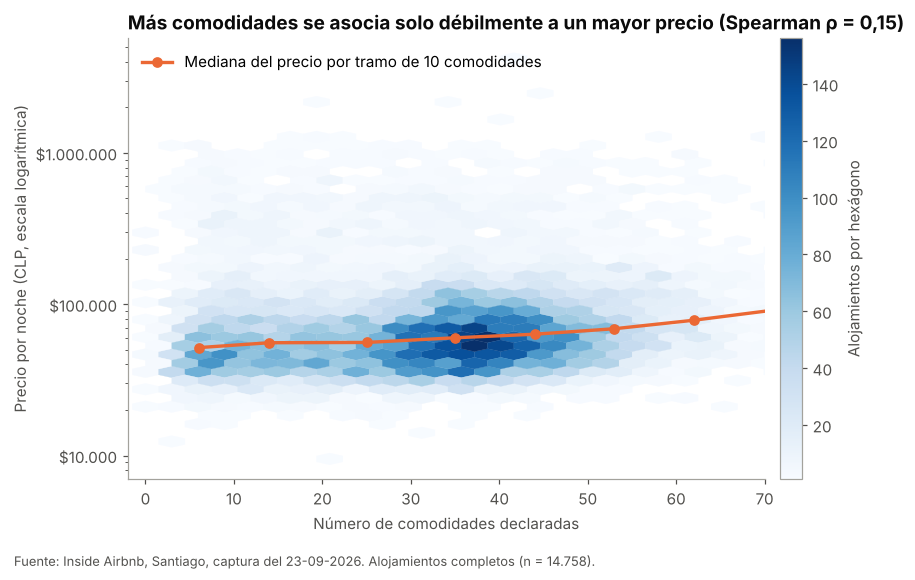

Figura guardada: F4/figuras_lab/lab_fig3_n_comodidades.png


In [11]:
rho = legible[["n_comodidades", "price"]].corr(method="spearman").iloc[0, 1]

tramos = pd.cut(legible["n_comodidades"], bins=range(0, legible["n_comodidades"].max() + 10, 10), right=False)
linea = legible.groupby(tramos, observed=True).agg(centro=("n_comodidades", "median"),
                                                   precio=("price", "median"), n=("price", "size"))
linea = linea[linea["n"] >= 30]       # tramos con pocos casos no se dibujan

fig, eje = plt.subplots(figsize=(9, 5.2))
hb = eje.hexbin(legible["n_comodidades"], legible["price"], gridsize=40, yscale="log",
                cmap="Blues", mincnt=1, linewidths=0.2)
eje.plot(linea["centro"], linea["precio"], color=NARANJA, linewidth=2.2, marker="o", markersize=6,
         label="Mediana del precio por tramo de 10 comodidades")
eje.yaxis.set_major_formatter(EJE_CLP)
eje.set_xlabel("Número de comodidades declaradas")
eje.set_ylabel("Precio por noche (CLP, escala logarítmica)")
barra = fig.colorbar(hb, ax=eje, pad=0.02)
barra.set_label("Alojamientos por hexágono", color=TINTA_2)
eje.legend(loc="upper left")
eje.set_xlim(-2, legible["n_comodidades"].quantile(0.995))
eje.set_title(f"Más comodidades se asocia solo débilmente a un mayor precio "
              f"(Spearman ρ = {decimal(rho, 2)})", fontsize=12.5)
pie_de_figura(fig, len(legible))
plt.show()
guardar(fig, "lab_fig3_n_comodidades")

**Cómo se lee.** La mediana del precio sube a medida que aumentan las comodidades, pero la nube de puntos es muy dispersa: la correlación de Spearman es baja (ρ = 0,15). La **cantidad** de comodidades se asocia poco con el precio; por eso la sección 7 revisa **cuáles** comodidades marcan diferencia.

---
## 7. Comodidades: ¿cuáles se asocian a precios altos?

Se compara qué porcentaje de alojamientos tiene cada comodidad entre los de **precio alto** (sobre la mediana) y los de **precio bajo** (bajo la mediana). La diferencia se muestra en puntos porcentuales con su intervalo de confianza.

Como se comparan **8 comodidades a la vez**, el intervalo se corrige por comparaciones múltiples (Bonferroni: 95 % conjunto, es decir 99,4 % para cada una). Aun así, el análisis es **exploratorio**: muestra asociaciones, no efectos.

In [12]:
COMODIDADES = [c for c in legible.columns if c.startswith("tiene_")]
NOMBRES = {c: c.replace("tiene_", "").replace("_", " ").capitalize() for c in COMODIDADES}
NOMBRES.update({"tiene_self_checkin": "Self check-in", "tiene_espacio_trabajo": "Espacio de trabajo",
                "tiene_aire_acondicionado": "Aire acondicionado"})
Z_BONF = 2.734      # z para alfa = 0,05 / 8 (dos colas)

mediana_precio = legible["price"].median()
alto = legible[legible["price"] > mediana_precio]
bajo = legible[legible["price"] <= mediana_precio]

filas = []
for c in COMODIDADES:
    p1, p0 = alto[c].mean(), bajo[c].mean()
    ee = np.sqrt(p1 * (1 - p1) / len(alto) + p0 * (1 - p0) / len(bajo))
    dif = (p1 - p0) * 100
    filas.append({"comodidad": NOMBRES[c], "pct_alto": p1 * 100, "pct_bajo": p0 * 100, "dif_pp": dif,
                  "ic_inf": dif - Z_BONF * ee * 100, "ic_sup": dif + Z_BONF * ee * 100})
prevalencia = pd.DataFrame(filas).sort_values("dif_pp").reset_index(drop=True)
prevalencia.round(1)

,comodidad,pct_alto,pct_bajo,dif_pp,ic_inf,ic_sup
0,Self check-in,67.3,65.7,1.7,-0.5,3.8
1,Ascensor,62.9,60.2,2.7,0.5,4.9
2,Gimnasio,31.2,28.5,2.7,0.7,4.8
3,Espacio de trabajo,52.8,47.3,5.5,3.3,7.7
4,Piscina,47.2,39.7,7.5,5.3,9.7
5,Lavadora,63.7,53.8,9.8,7.6,12.0
6,Estacionamiento,81.6,63.3,18.3,16.4,20.3
7,Aire acondicionado,46.3,27.5,18.8,16.7,20.9


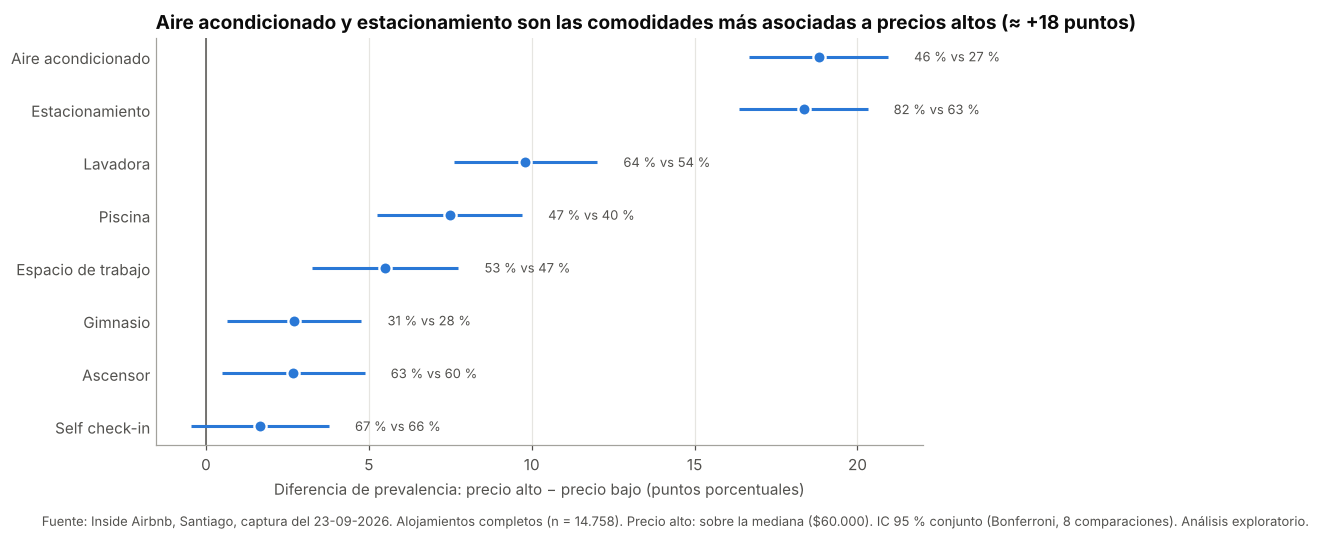

Figura guardada: F4/figuras_lab/lab_fig4_comodidades.png


In [13]:
fig, eje = plt.subplots(figsize=(9, 4.8))
y = np.arange(len(prevalencia))
eje.axvline(0, color=TINTA_2, linewidth=1)
eje.hlines(y, prevalencia["ic_inf"], prevalencia["ic_sup"], color=AZUL, linewidth=2)
eje.plot(prevalencia["dif_pp"], y, "o", color=AZUL, markersize=8,
         markeredgecolor="white", markeredgewidth=1.5)
for yi, fila in prevalencia.iterrows():
    eje.text(fila["ic_sup"] + 0.8, yi, f"{decimal(fila['pct_alto'], 0)} % vs {decimal(fila['pct_bajo'], 0)} %",
             va="center", fontsize=8.5, color=TINTA_2)
eje.set_yticks(y, prevalencia["comodidad"])
eje.tick_params(axis="y", length=0)
eje.set_xlabel("Diferencia de prevalencia: precio alto − precio bajo (puntos porcentuales)")
eje.grid(axis="x")
eje.set_axisbelow(True)
mayor, segunda = prevalencia.iloc[-1], prevalencia.iloc[-2]
eje.set_title(f"{mayor['comodidad']} y {segunda['comodidad'].lower()} son las comodidades más "
              f"asociadas a precios altos (≈ +{decimal(segunda['dif_pp'], 0)} puntos)", fontsize=12.5)
pie_de_figura(fig, len(legible), f"Precio alto: sobre la mediana (${miles(mediana_precio)}). "
              "IC 95 % conjunto (Bonferroni, 8 comparaciones). Análisis exploratorio.")
plt.show()
guardar(fig, "lab_fig4_comodidades")

### 7.1 ¿La diferencia se mantiene al controlar ubicación y capacidad?

Una comodidad puede aparecer asociada a precios altos solo porque es más frecuente en comunas caras o en alojamientos grandes (confusión). Para revisarlo, se calcula la diferencia de **mediana de precio** entre alojamientos con y sin cada comodidad de tres formas: en todo el conjunto, **dentro de cada tramo de capacidad** y **dentro de cada comuna**, y luego se promedian las diferencias de los estratos ponderando por su tamaño. Solo cuentan los estratos con al menos 30 alojamientos en cada grupo.

In [14]:
def diferencia_estratificada(df, comodidad, estrato=None, minimo=30):
    # Diferencia de mediana de precio (con - sin), global o promediada dentro de estratos
    if estrato is None:
        return df.loc[df[comodidad] == 1, "price"].median() - df.loc[df[comodidad] == 0, "price"].median()
    difs, pesos = [], []
    for _, sub in df.groupby(estrato, observed=True):
        con, sin = sub[sub[comodidad] == 1], sub[sub[comodidad] == 0]
        if len(con) >= minimo and len(sin) >= minimo:
            difs.append(con["price"].median() - sin["price"].median())
            pesos.append(len(sub))
    return np.average(difs, weights=pesos) if difs else np.nan


confusion = pd.DataFrame([{
    "comodidad": NOMBRES[c],
    "global": diferencia_estratificada(legible, c),
    "dentro_capacidad": diferencia_estratificada(legible, c, "capacidad"),
    "dentro_comuna": diferencia_estratificada(legible, c, "comuna_grupo"),
} for c in COMODIDADES]).set_index("comodidad").sort_values("global", ascending=False)

confusion.map(lambda v: f"${miles(v)}" if pd.notna(v) else "sin datos")

,global,dentro_capacidad,dentro_comuna
comodidad,,,
Estacionamiento,$14.998,$12.844,$7.801
Aire acondicionado,$14.036,$1.526,$-2.416
Lavadora,$7.898,$-3.305,$7.347
Piscina,$5.623,$2.344,$-2.896
Espacio de trabajo,$3.571,$-8.443,$-1.129
Gimnasio,$1.873,$-2.040,$6.221
Ascensor,$1.747,$1.861,$6.716
Self check-in,$675,$-8.704,$5.550


**Cómo se lee.** Si la diferencia baja mucho al pasar de "global" a "dentro de capacidad" o "dentro de comuna", parte de la asociación se explicaba por la ubicación o el tamaño del alojamiento, no por la comodidad.

- **Aire acondicionado:** la diferencia global de unos $14.000 casi desaparece al comparar dentro de un mismo tramo de capacidad (unos $1.500) y se vuelve negativa dentro de una misma comuna. Su asociación con el precio se explica sobre todo por **dónde** están y **qué tamaño** tienen esos alojamientos.
- **Estacionamiento:** es la asociación más robusta: se mantiene dentro de capacidad (unos $12.800) y, más baja, dentro de comuna (unos $7.800).
- El resto de las comodidades muestra diferencias pequeñas que cambian de signo según el control: no permiten concluir.

Aun así, es una asociación y no un efecto causal: es una sola captura.

---
## 8. Estabilidad entre entrenamiento y prueba

**Qué cuenta como patrón estable:** que el **orden de las comunas por mediana de precio** sea similar en entrenamiento y en prueba. Se mide con la correlación de Spearman entre ambos rankings (1 = mismo orden). Se repite para los tramos de capacidad y para el orden de las comodidades.

In [15]:
def ranking_estable(columna_grupo, valor="price", minimo=10):
    # Spearman entre la mediana por grupo en entrenamiento y en prueba
    med = legible.groupby([columna_grupo, "conjunto"], observed=True)[valor].agg(["median", "size"]).unstack()
    med = med[(med["size"] >= minimo).all(axis=1)]
    return med["median"].corr(method="spearman").iloc[0, 1], len(med)


def ranking_comodidades():
    difs = {}
    for conj, sub in legible.groupby("conjunto"):
        m = sub["price"].median()
        difs[conj] = [sub.loc[sub["price"] > m, c].mean() - sub.loc[sub["price"] <= m, c].mean()
                      for c in COMODIDADES]
    return pd.DataFrame(difs).corr(method="spearman").iloc[0, 1], len(COMODIDADES)


estabilidad = pd.DataFrame([
    ("Comunas por mediana de precio", *ranking_estable("comuna_grupo")),
    ("Capacidad por mediana de precio", *ranking_estable("capacidad")),
    ("Comunas por mediana de ocupación (>0)", *ranking_estable("comuna_grupo", "ocupacion_positiva")),
    ("Comodidades por diferencia de prevalencia", *ranking_comodidades()),
], columns=["patrón", "spearman", "grupos"])
estabilidad["spearman"] = estabilidad["spearman"].round(2)
estabilidad

,patrón,spearman,grupos
0,Comunas por mediana de precio,0.88,17
1,Capacidad por mediana de precio,1.00,7
2,Comunas por mediana de ocupación (>0),0.88,17
3,Comodidades por diferencia de prevalencia,0.93,8


**Cómo se lee.** Los cuatro patrones se repiten en entrenamiento y prueba: el orden de las comunas por precio (ρ = 0,88), el de los tramos de capacidad (ρ = 1,00) y el de las comodidades (ρ = 0,93). Los hallazgos no dependen de qué alojamientos quedaron en cada parte.

---
## 9. Tabla de hallazgos y limitaciones

Cada cifra indica la sección del cuaderno que la produce. El informe y el video deben usar **estas mismas cifras**.

In [16]:
c1, c2 = tabla_comunas.drop(index=[i for i in tabla_comunas.index if i.startswith("Otras")]).index[:2]
cap = tabla_capacidad["mediana"]
hallazgos = pd.DataFrame([
    ("3", "Ocupación 0", f"{decimal(pct_cero)} % de los alojamientos"),
    ("3", "Ocupación en el tope", f"{decimal(pct_tope)} % ({miles(TOPE)} noches)"),
    ("4", "Comuna con mayor precio mediano", f"{c1}: ${miles(tabla_comunas.loc[c1, 'precio_mediana'])}"),
    ("4", "Segunda comuna con mayor precio", f"{c2}: ${miles(tabla_comunas.loc[c2, 'precio_mediana'])}"),
    ("5", "Precio mediano, 2 huéspedes", f"${miles(cap.iloc[1])}"),
    ("5", "Precio mediano, 9 o más huéspedes", f"${miles(cap.iloc[-1])}"),
    ("6", "Spearman comodidades vs precio", decimal(rho, 2)),
    ("7", "Comodidad más asociada a precio alto", f"{mayor['comodidad']} (+{decimal(mayor['dif_pp'])} pp)"),
    ("8", "Estabilidad del ranking de comunas", decimal(estabilidad.loc[0, "spearman"], 2)),
], columns=["seccion", "hallazgo", "cifra"])

DIR_DOCS.mkdir(exist_ok=True)
hallazgos.to_csv(DIR_DOCS / "hallazgos_f4_lab.csv", index=False)
hallazgos

,seccion,hallazgo,cifra
0,3,Ocupación 0,"17,6 % de los alojamientos"
1,3,Ocupación en el tope,"10,5 % (255 noches)"
2,4,Comuna con mayor precio mediano,Lo Barnechea: $391.834
3,4,Segunda comuna con mayor precio,Vitacura: $136.667
4,5,"Precio mediano, 2 huéspedes",$49.767
5,5,"Precio mediano, 9 o más huéspedes",$422.367
6,6,Spearman comodidades vs precio,"0,15"
7,7,Comodidad más asociada a precio alto,"Aire acondicionado (+18,8 pp)"
8,8,Estabilidad del ranking de comunas,"0,88"


### Limitaciones

- **Precio publicado**, no precio pagado, y de una **sola captura** (23-09-2026): no permite ver estacionalidad ni cambios en el tiempo.
- **La ocupación es estimada** a partir de las reseñas, con muchos ceros y un tope; no es la ocupación real.
- **Supervivencia de anuncios:** solo aparecen los alojamientos activos en la fecha de captura.
- **Asociación, no causalidad:** es un corte transversal. Usamos "se asocia" o "presenta mayor precio", nunca "causa".
- **Comunas pequeñas** agrupadas: no se puede concluir nada sobre cada una de ellas por separado.